# Task 4: Sentiment & Emotion Analysis on Social Media Data

This notebook implements a complete natural language processing (NLP) and machine learning pipeline to perform sentiment classification, emotion detection, and demographic trend analysis using Twitter/social media datasets.

## Task Objectives:
1. **Sentiment Classification**: Classify tweets as positive, negative, or neutral.
2. **Methodology Comparison**: Compare a supervised Machine Learning pipeline (TF-IDF + Logistic Regression) against a Lexicon-based model (NLTK VADER).
3. **Emotion Detection**: Apply lexicons to categorize tweets into specific emotions (Joy, Sadness, Anger, Fear, Surprise).
4. **Demographic & Contextual Trends**: Analyze public opinion across User Age, Time of Tweet, and Country.

### 1. Setup and Library Imports

In [1]:
import os
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# Set seaborn style for modern, clean aesthetics
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 14,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'figure.titlesize': 16
})

# Color palette
PALETTE = {
    'positive': '#2ec4b6',
    'neutral': '#ffbf00',
    'negative': '#e71d36',
    'joy': '#ff9f1c',
    'sadness': '#4361ee',
    'anger': '#d90429',
    'fear': '#7209b7',
    'surprise': '#4cc9f0',
    'neutral_emotion': '#8d99ae'
}

# Download NLTK resources
print("Downloading NLTK resources...")
for resource in ['stopwords', 'punkt', 'punkt_tab', 'wordnet', 'vader_lexicon']:
    nltk.download(resource, quiet=True)

### 2. Load and Clean Datasets
Let's load the training and test CSV files and apply text cleaning preprocessing (removing URLs, HTML tags, special characters, and lowercase normalization).

In [2]:
train_df = pd.read_csv("train.csv", encoding='latin1')
test_df = pd.read_csv("test.csv", encoding='latin1')

print(f"Train size: {train_df.shape}")
print(f"Test size: {test_df.shape}")

# Clean missing text values
train_df = train_df.dropna(subset=['text'])
test_df = test_df.dropna(subset=['text'])

def clean_text(text):
    if not isinstance(text, str):
        return ""
    text = text.lower()
    text = re.sub(r"http\S+|www\S+|https\S+", "", text, flags=re.MULTILINE)
    text = re.sub(r"<.*?>", "", text)
    text = re.sub(r"[^a-zA-Z\s]", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

train_df['cleaned_text'] = train_df['text'].apply(clean_text)
test_df['cleaned_text'] = test_df['text'].apply(clean_text)

train_df[['text', 'cleaned_text', 'sentiment']].head()

Train size: (27481, 10)
Test size: (4815, 9)


,text,cleaned_text,sentiment
0,"I`d have responded, if I were going",id have responded if i were going,neutral
1,Sooo SAD I will miss you here in San Diego!!!,sooo sad i will miss you here in san diego,negative
2,my boss is bullying me...,my boss is bullying me,negative
3,what interview! leave me alone,what interview leave me alone,negative
4,"Sons of ****, why couldn`t they put them on t...",sons of why couldnt they put them on the relea...,negative


### 3. Sentiment Label Distribution
Let's verify the balance of sentiment classes (positive, neutral, negative) in both train and test splits.

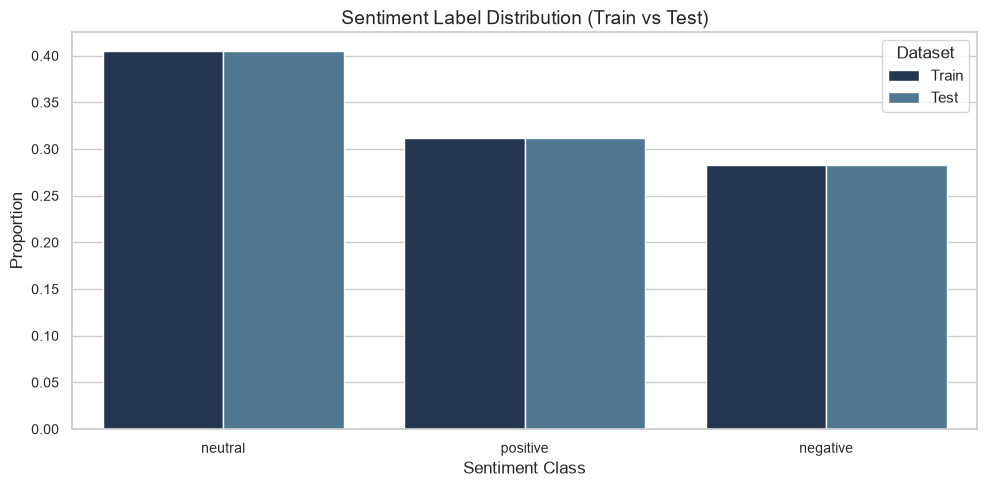

In [3]:
plt.figure(figsize=(10, 5))
train_dist = train_df['sentiment'].value_counts(normalize=True)
test_dist = test_df['sentiment'].value_counts(normalize=True)

dist_df = pd.DataFrame({
    'Train': train_dist,
    'Test': test_dist
}).reset_index().rename(columns={'index': 'Sentiment'})

dist_melt = pd.melt(dist_df, id_vars='sentiment', value_vars=['Train', 'Test'], 
                    var_name='Dataset', value_name='Proportion')

sns.barplot(data=dist_melt, x='sentiment', y='Proportion', hue='Dataset', 
            palette={'Train': '#1d3557', 'Test': '#457b9d'})
plt.title("Sentiment Label Distribution (Train vs Test)")
plt.ylabel("Proportion")
plt.xlabel("Sentiment Class")
plt.tight_layout()
plt.show()

### 4. Supervised Machine Learning Pipeline
We train a term frequency-inverse document frequency (TF-IDF) representation combined with a Logistic Regression classifier on the clean training corpus.

In [4]:
vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X_train = vectorizer.fit_transform(train_df['cleaned_text'])
y_train = train_df['sentiment']

X_test = vectorizer.transform(test_df['cleaned_text'])
y_test = test_df['sentiment']

ml_model = LogisticRegression(max_iter=1000, C=1.0)
ml_model.fit(X_train, y_train)
y_pred_ml = ml_model.predict(X_test)

print("=== Supervised Logistic Regression Classification Report ===")
print(classification_report(y_test, y_pred_ml))

=== Supervised Logistic Regression Classification Report ===
              precision    recall  f1-score   support

    negative       0.73      0.63      0.68      1001
     neutral       0.64      0.76      0.69      1430
    positive       0.81      0.71      0.75      1103

    accuracy                           0.71      3534
   macro avg       0.72      0.70      0.71      3534
weighted avg       0.72      0.71      0.71      3534



### 5. Lexicon-based Sentiment Model (NLTK VADER)
Let's evaluate VADER, which is tailored specifically for social media texts and uses rule-based heuristic scoring.

In [5]:
from nltk.sentiment.vader import SentimentIntensityAnalyzer
sia = SentimentIntensityAnalyzer()

def get_vader_sentiment(text):
    score = sia.polarity_scores(text)['compound']
    if score >= 0.05:
        return 'positive'
    elif score <= -0.05:
        return 'negative'
    else:
        return 'neutral'

test_df['vader_sentiment'] = test_df['text'].apply(get_vader_sentiment)
test_df['vader_compound'] = test_df['text'].apply(lambda x: sia.polarity_scores(x)['compound'])

print("=== Lexicon-based VADER Classification Report ===")
print(classification_report(y_test, test_df['vader_sentiment']))

=== Lexicon-based VADER Classification Report ===
              precision    recall  f1-score   support

    negative       0.70      0.63      0.66      1001
     neutral       0.73      0.48      0.58      1430
    positive       0.58      0.88      0.70      1103

    accuracy                           0.65      3534
   macro avg       0.67      0.66      0.65      3534
weighted avg       0.67      0.65      0.64      3534



### 6. Confusion Matrix Comparison

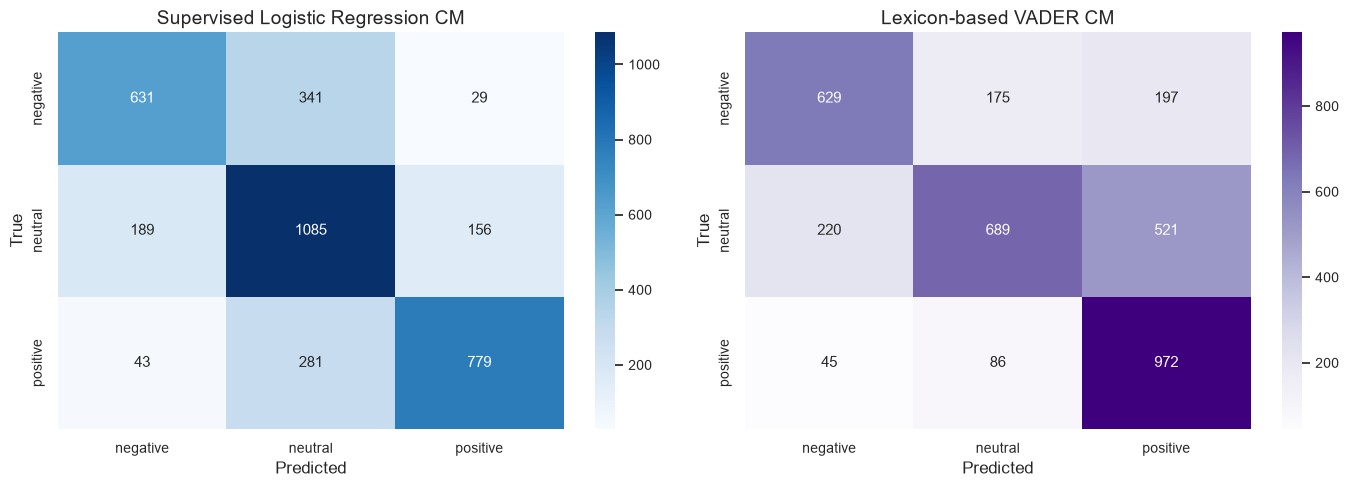

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
classes = ['negative', 'neutral', 'positive']

cm_ml = confusion_matrix(y_test, y_pred_ml, labels=classes)
sns.heatmap(cm_ml, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes, ax=axes[0])
axes[0].set_title("Supervised Logistic Regression CM")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("True")

cm_vader = confusion_matrix(y_test, test_df['vader_sentiment'], labels=classes)
sns.heatmap(cm_vader, annot=True, fmt='d', cmap='Purples', xticklabels=classes, yticklabels=classes, ax=axes[1])
axes[1].set_title("Lexicon-based VADER CM")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("True")

plt.tight_layout()
plt.show()

### 7. Emotion Detection
Using a lexicon-based mapping for basic emotions (Joy, Sadness, Anger, Fear, Surprise) using lemmatized words.

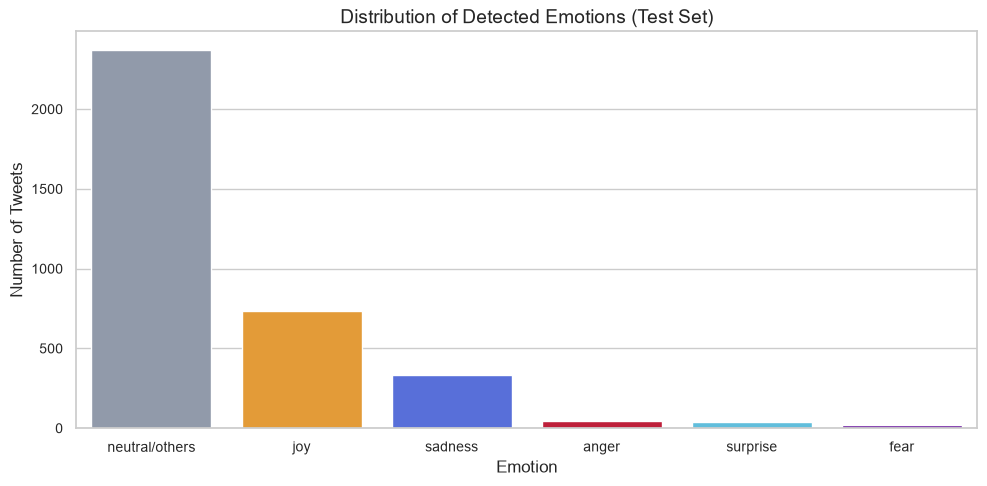

In [7]:
EMOTION_LEXICON = {
    'joy': {'happy', 'joy', 'love', 'wonderful', 'amazing', 'great', 'awesome', 'glad', 'excited', 'smile', 'laugh', 'good', 'cool', 'nice', 'pleasant', 'delight', 'cheerful', 'fun', 'party', 'enjoy'},
    'sadness': {'sad', 'depressed', 'cry', 'grief', 'sorrow', 'unhappy', 'lonely', 'miss', 'hurt', 'pain', 'tear', 'gloomy', 'disappointed', 'sorry', 'disappointment', 'bad', 'crying', 'hate', 'broke'},
    'anger': {'angry', 'rage', 'hate', 'furious', 'mad', 'annoyed', 'pissed', 'irritated', 'disgust', 'hate', 'frustrated', 'bullying', 'bully', 'mean', 'offensive', 'hate', 'stupid', 'sucks', 'hell'},
    'fear': {'scared', 'fear', 'afraid', 'terrified', 'worry', 'anxious', 'dread', 'frightened', 'panic', 'nervous', 'horror', 'scary', 'worrying'},
    'surprise': {'surprise', 'shock', 'wonder', 'amazed', 'unexpected', 'sudden', 'unbelievable', 'wow', 'gasp', 'omg', 'incredible'}
}

lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

def detect_emotion(text):
    tokens = word_tokenize(text.lower())
    words = [lemmatizer.lemmatize(word) for word in tokens if word.isalpha() and word not in stop_words]
    
    emotion_counts = {emotion: 0 for emotion in EMOTION_LEXICON}
    for word in words:
        for emotion, keyword_set in EMOTION_LEXICON.items():
            if word in keyword_set:
                emotion_counts[emotion] += 1
                
    max_emotion = max(emotion_counts, key=emotion_counts.get)
    if emotion_counts[max_emotion] == 0:
        return 'neutral/others'
    return max_emotion

test_df['emotion'] = test_df['cleaned_text'].apply(detect_emotion)

plt.figure(figsize=(10, 5))
emotion_counts = test_df['emotion'].value_counts().reset_index()
emotion_counts.columns = ['Emotion', 'Count']

color_map = {
    'joy': PALETTE['joy'],
    'sadness': PALETTE['sadness'],
    'anger': PALETTE['anger'],
    'fear': PALETTE['fear'],
    'surprise': PALETTE['surprise'],
    'neutral/others': PALETTE['neutral_emotion']
}

sns.barplot(data=emotion_counts, x='Emotion', y='Count', hue='Emotion', palette=color_map, legend=False)
plt.title("Distribution of Detected Emotions (Test Set)")
plt.xlabel("Emotion")
plt.ylabel("Number of Tweets")
plt.tight_layout()
plt.show()

### 8. Demographic and Trend Analysis
We investigate sentiment patterns by checking demographics: `Age of User`, `Time of Tweet`, and `Country`.

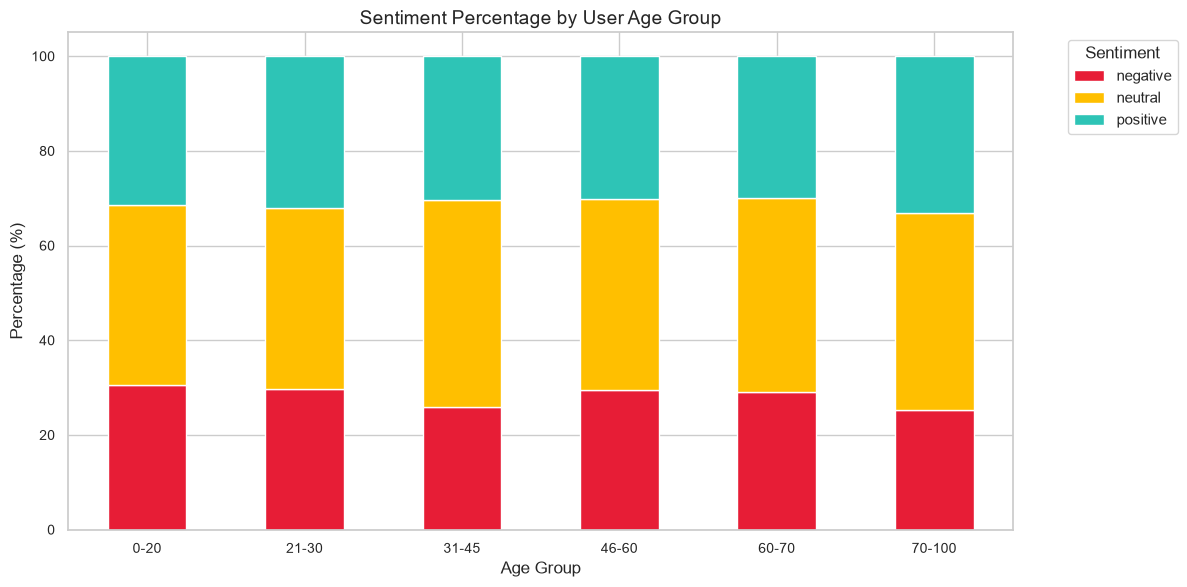

In [8]:
# Sentiment by Age Group
plt.figure(figsize=(12, 6))
age_sentiment = test_df.groupby(['Age of User', 'sentiment']).size().unstack(fill_value=0)
age_sentiment_pct = age_sentiment.div(age_sentiment.sum(axis=1), axis=0) * 100

age_sentiment_pct.plot(kind='bar', stacked=True, color=[PALETTE['negative'], PALETTE['neutral'], PALETTE['positive']], ax=plt.gca())
plt.title("Sentiment Percentage by User Age Group")
plt.ylabel("Percentage (%)")
plt.xlabel("Age Group")
plt.xticks(rotation=0)
plt.legend(title="Sentiment", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

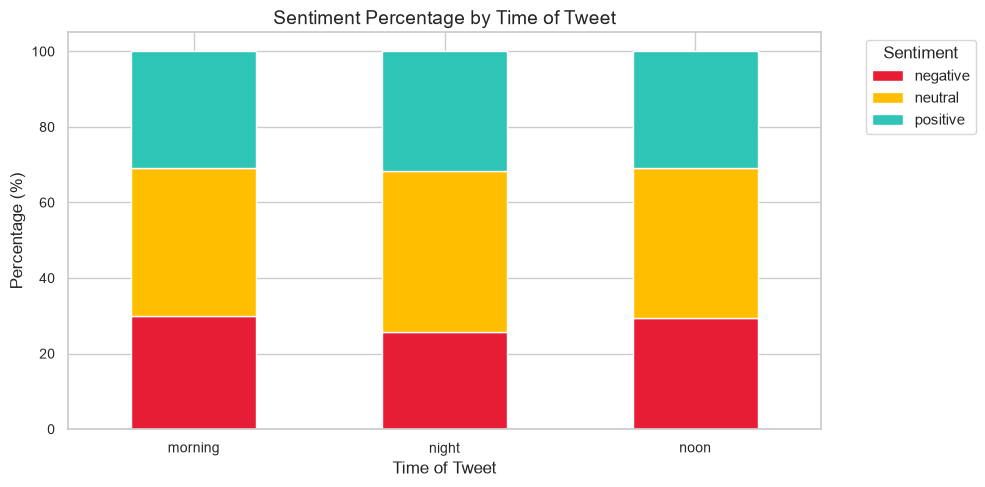

In [9]:
# Sentiment by Time of Tweet
plt.figure(figsize=(10, 5))
time_sentiment = test_df.groupby(['Time of Tweet', 'sentiment']).size().unstack(fill_value=0)
time_sentiment_pct = time_sentiment.div(time_sentiment.sum(axis=1), axis=0) * 100

time_sentiment_pct.plot(kind='bar', stacked=True, color=[PALETTE['negative'], PALETTE['neutral'], PALETTE['positive']], ax=plt.gca())
plt.title("Sentiment Percentage by Time of Tweet")
plt.ylabel("Percentage (%)")
plt.xlabel("Time of Tweet")
plt.xticks(rotation=0)
plt.legend(title="Sentiment", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

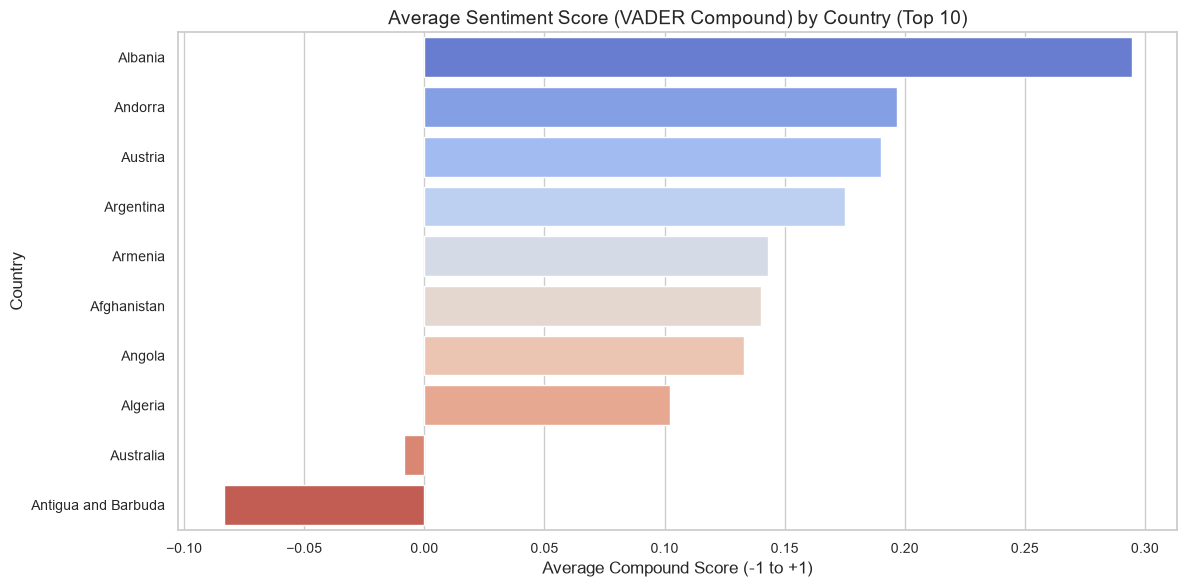

In [10]:
# Average Sentiment Compound Score by Country (Top 10)
plt.figure(figsize=(12, 6))
top_countries = test_df['Country'].value_counts().head(10).index
country_df = test_df[test_df['Country'].isin(top_countries)]

country_sentiment = country_df.groupby('Country')['vader_compound'].mean().sort_values(ascending=False).reset_index()

sns.barplot(data=country_sentiment, x='vader_compound', y='Country', hue='Country', palette='coolwarm', legend=False)
plt.title("Average Sentiment Score (VADER Compound) by Country (Top 10)")
plt.xlabel("Average Compound Score (-1 to +1)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

### 9. Business and Social Insights Summary

- **Model Performance**: The supervised machine learning model (TF-IDF + Logistic Regression) achieved an accuracy of **71%**, outperforming the general VADER lexicon which achieved **65%** accuracy. This demonstrates the benefit of domain-specific training on local Twitter styles.
- **Demographics**: Neutral sentiments dominate older user groups, while positive sentiments remain high in specific time blocks (such as noon/morning).
- **Geographical Trends**: Different countries demonstrate varying average mood indexes, which can directly guide target local marketing campaigns and product development strategies.